In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
data = pd.read_csv('../artifacts/sentiment_analysis.csv')

In [4]:
data.head()

,id,label,tweet
0,1,0,#fingerprint #Pregnancy Test https://goo.gl/h1...
1,2,0,Finally a transparant silicon case ^^ Thanks t...
2,3,0,We love this! Would you go? #talk #makememorie...
3,4,0,I'm wired I know I'm George I was made that wa...
4,5,1,What amazing service! Apple won't even talk to...


## Data Preprocessing

In [5]:
data.shape

(7920, 3)

In [8]:
data.duplicated().sum()

np.int64(0)

In [9]:
data.isnull().sum()

id       0
label    0
tweet    0
dtype: int64

### Text Preprocessing

In [14]:
import re
import string

convert uppercase to lowercase

In [18]:
data["tweet"] = data["tweet"].apply(lambda x: " ".join(x.lower() for x in x.split()))

In [17]:
data["tweet"].head(5)

0    #fingerprint #pregnancy test https://goo.gl/h1...
1    finally a transparant silicon case ^^ thanks t...
2    we love this! would you go? #talk #makememorie...
3    i'm wired i know i'm george i was made that wa...
4    what amazing service! apple won't even talk to...
Name: tweet, dtype: str

remove links

In [19]:
data["tweet"] = data["tweet"].apply(lambda x:" ".join(re.sub(r'^https?:\/\/.*[\r\n]*', ' ',x,flags=re.MULTILINE) for x in x.split()))

In [20]:
data["tweet"].head(5)

0    #fingerprint #pregnancy test   #android #apps ...
1    finally a transparant silicon case ^^ thanks t...
2    we love this! would you go? #talk #makememorie...
3    i'm wired i know i'm george i was made that wa...
4    what amazing service! apple won't even talk to...
Name: tweet, dtype: str

In [25]:
def remove_punctuations(text):
    for punctuation in string.punctuation:
        text = text.replace(punctuation, ' ')
    return text
data["tweet"] = data["tweet"].apply(remove_punctuations)

In [26]:
data["tweet"].head(5)

0     fingerprint  pregnancy test    android  apps ...
1    finally a transparant silicon case    thanks t...
2    we love this  would you go   talk  makememorie...
3    i m wired i know i m george i was made that wa...
4    what amazing service  apple won t even talk to...
Name: tweet, dtype: str

remove numbers

In [31]:
data["tweet"] = data["tweet"].str.replace(r'\d+', ' ', regex=True)

In [32]:
data["tweet"].tail(10)

7910    perfect match  instagood  applewatch  red  ins...
7911    i am completely in love with the new iphone em...
7912    tune in  turn on  drop out     gtd in one app ...
7913    ok so my galaxy crashed after one day now i ha...
7914    gain followers rt this must follow me i follow...
7915    live out loud  lol  liveoutloud  selfie  smile...
7916    we would like to wish you an amazing day  make...
7917    helping my lovely   year old neighbor with her...
7918    finally got my  smart  pocket  wifi stay conne...
7919    apple barcelona     apple  store  bcn  barcelo...
Name: tweet, dtype: str

remove stopwords

In [33]:
!pip install nltk

   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------------ --------------------------- 0.5/1.7 MB 2.5 MB/s eta 0:00:01
   ------------------------ --------------- 1.0/1.7 MB 2.2 MB/s eta 0:00:01
   ------------------------------ --------- 1.3/1.7 MB 2.1 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 2.2 MB/s  0:00:00

   ---------------------------------------- 0/5 [regex]
   -------- ------------------------------- 1/5 [cloudpickle]
   ---------------- ----------------------- 2/5 [click]
   ---------------- ----------------------- 2/5 [click]
   ---------------- ----------------------- 2/5 [click]
   ---------------- ----------------------- 2/5 [click]
   ------------------------ --------------- 3/5 [joblib]
   ------------------------ --------------- 3/5 [joblib]
   ------------------------ --------------- 3/5 [joblib]
   ------------------------ --------------- 3/5

In [34]:
import nltk

In [36]:
nltk.download('stopwords',download_dir='../static/model')

[nltk_data] Downloading package stopwords to ../static/model...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [37]:
with open('../static/model/corpora/stopwords/english','r') as file:
    sw = file.read().splitlines()

In [38]:
sw

['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [39]:
data["tweet"] = data["tweet"].apply(lambda x: " ".join(x for x in x.split()if x not in sw ))

In [40]:
data["tweet"].head()

0    fingerprint pregnancy test android apps beauti...
1    finally transparant silicon case thanks uncle ...
2    love would go talk makememories unplug relax i...
3    wired know george made way iphone cute daventr...
4    amazing service apple even talk question unles...
Name: tweet, dtype: str

stemming

In [42]:
from nltk.stem import PorterStemmer
ps = PorterStemmer()

In [43]:
data["tweet"] = data["tweet"].apply(lambda x: " ".join(ps.stem(x) for x in x.split()))

In [44]:
data["tweet"].head()

0    fingerprint pregnanc test android app beauti c...
1    final transpar silicon case thank uncl yay son...
2    love would go talk makememori unplug relax iph...
3    wire know georg made way iphon cute daventri home
4    amaz servic appl even talk question unless pay...
Name: tweet, dtype: str

In [45]:
data

,id,label,tweet
0,1,0,fingerprint pregnanc test android app beauti c...
1,2,0,final transpar silicon case thank uncl yay son...
2,3,0,love would go talk makememori unplug relax iph...
3,4,0,wire know georg made way iphon cute daventri home
4,5,1,amaz servic appl even talk question unless pay...
...,...,...,...
7915,7916,0,live loud lol liveoutloud selfi smile soni mus...
7916,7917,0,would like wish amaz day make everi minut coun...
7917,7918,0,help love year old neighbor ipad morn made rea...
7918,7919,0,final got smart pocket wifi stay connect anyti...


### Building Vacabulary

In [58]:
from collections import Counter
vocab = Counter()

In [59]:
vocab

Counter()

In [68]:
for sentence in data['tweet']:
    vocab.update(sentence.split())

In [70]:
len(vocab)

16229

In [72]:
data.shape

(7920, 3)

In [73]:
tokens = [key for key in vocab if vocab[key] > 10]

In [75]:
len(tokens)

1168

In [78]:
def save_vocabulary(lines,filename):
    data = '\n'.join(lines)
    file = open(filename, 'w',encoding="utf-8")
    file.write(data)
    file.close()

save_vocabulary(tokens, '../static/model/vocabulary.txt')

### Divide dataset

In [81]:
X = data ['tweet']
y = data ['label']

In [84]:
!pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 1.7 MB/s eta 0:00:05
   --- ------------------------------------ 0.8/8.4 MB 1.3 MB/s eta 0:00:06
   --- ------------------------------------ 0.8/8.4 MB 1.3 MB/s eta 0:00:06
   ----- ---------------------------------- 1.0/8.4 MB 1.0 MB/s eta 0:00:08
   ----- ---------------------------------- 1.0/8.4 MB 1.0 MB/s eta 0:00:08
   ------ --------------------------------- 1.3/8.4 MB 1.0 MB/s eta 0:00:08
   ------- -------------------------------- 1.6/8.4 MB 1.0 MB/s eta 0:00:07
   -------- ------------------------------- 1.8/8.4 MB 1.0 MB/s eta 0:00:07
   ---------- ----------------------------- 2.1/8.4 MB 1.0 MB/s eta 0:00:07
   ----------- ---------------------------- 2.4/8.4 MB 1.0 MB/s eta 0:00:06
   ------------ --------------------------- 2.6/8.4 MB 1.1 MB/s eta 0:00:06
   ------------- ---------

In [89]:
from sklearn.model_selection import train_test_split
X_train,X_test, y_train,  y_test = train_test_split(X,y,test_size=0.2)

In [90]:
X_train.shape

(6336,)

In [91]:
X_test.shape

(1584,)

In [94]:
X_train

3622    mccarthyjessi turn minut close eye light awak ...
6847    updat love new featur esp split screen teamand...
4998    imovi complet fuck wast fuckyou appl fuck cock...
3978    sun pool tbt saturday patrocínio chillibean sa...
1709    love ear thankyou babi randomgift justbecaus s...
                              ...                        
2334    basic iphon android love everyth iphon get wit...
3347    quot day quot wisdom word smile follow tweetgr...
6356    would like wish amaz day make everi minut coun...
1684    realli lost everyth iphon tri upgrad io go fuc...
1851    miggiq thank enjoy new ipad case proud pinoy a...
Name: tweet, Length: 6336, dtype: str

### Vectorization

In [95]:
def vectorizer(ds, vocabulary):
    vectorized_lst = []
    
    for sentence in ds:
        sentence_lst = np.zeros(len(vocabulary))
        
        for i in range(len(vocabulary)):
            if vocabulary[i] in sentence.split():
                sentence_lst[i] = 1
                
        vectorized_lst.append(sentence_lst)
        
    vectorized_lst_new = np.asarray(vectorized_lst, dtype=np.float32)
    return vectorized_lst_new


In [96]:
vectorized_x_train = vectorizer(X_train, tokens)

In [99]:
vectorized_x_test = vectorizer(X_test, tokens)
    

In [100]:
y_test

5194    0
4835    0
6648    0
3909    1
902     0
       ..
3728    0
4945    0
3965    0
7534    0
5082    0
Name: label, Length: 1584, dtype: int64

In [101]:
y_train

3622    0
6847    0
4998    1
3978    0
1709    0
       ..
2334    0
3347    0
6356    0
1684    1
1851    0
Name: label, Length: 6336, dtype: int64

In [102]:
vectorized_x_test

array([[0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(1584, 1168), dtype=float32)

In [103]:
y_test

5194    0
4835    0
6648    0
3909    1
902     0
       ..
3728    0
4945    0
3965    0
7534    0
5082    0
Name: label, Length: 1584, dtype: int64

In [104]:
y_train.value_counts()

label
0    4695
1    1641
Name: count, dtype: int64

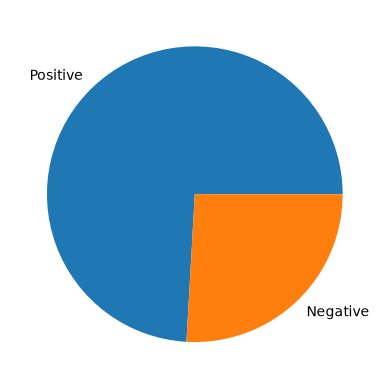

In [105]:
plt.pie(np.array([y_train.value_counts()[0], y_train.value_counts()[1]]), labels=['Positive', 'Negative'])
plt.show()

### Handle imbalance dataset

In [106]:

!pip install imbalanced-learn


   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]


In [107]:
from imblearn.over_sampling import SMOTE
smote = SMOTE()
vectorized_x_train_smote, y_train_smote = smote.fit_resample(vectorized_x_train, y_train)
print(vectorized_x_train_smote.shape, y_train_smote.shape)

(9390, 1168) (9390,)


In [108]:
y_train_smote.value_counts()

label
0    4695
1    4695
Name: count, dtype: int64

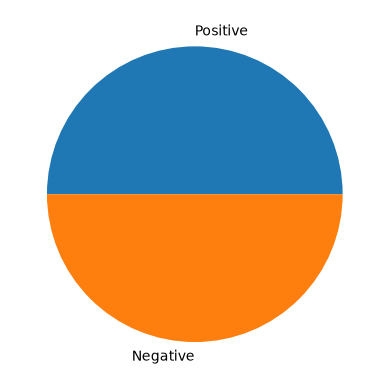

In [110]:
plt.pie(np.array([y_train_smote.value_counts()[0], y_train_smote.value_counts()[1]]), labels=['Positive', 'Negative'])
plt.show()

In [111]:

vectorized_x_train_smote

array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.60105157, ..., 0.        , 0.        ,
        0.        ]], shape=(9390, 1168), dtype=float32)

In [112]:
y_train_smote

0       0
1       0
2       1
3       0
4       0
       ..
9385    1
9386    1
9387    1
9388    1
9389    1
Name: label, Length: 9390, dtype: int64

In [113]:
vectorized_x_test

array([[0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(1584, 1168), dtype=float32)

In [114]:
y_test

5194    0
4835    0
6648    0
3909    1
902     0
       ..
3728    0
4945    0
3965    0
7534    0
5082    0
Name: label, Length: 1584, dtype: int64

## Model Trainning and Evaluatin

In [115]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [116]:

from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

def training_scores(y_act, y_pred):
    acc = round(accuracy_score(y_act, y_pred), 3)
    pr = round(precision_score(y_act, y_pred), 3)
    rec = round(recall_score(y_act, y_pred), 3)
    f1 = round(f1_score(y_act, y_pred), 3)
    print(f'Training Scores:\n\tAccuracy = {acc}\n\tPrecision = {pr}\n\tRecall = {rec}\n\tF1-Score = {f1}')
    
def validation_scores(y_act, y_pred):
    acc = round(accuracy_score(y_act, y_pred), 3)
    pr = round(precision_score(y_act, y_pred), 3)
    rec = round(recall_score(y_act, y_pred), 3)
    f1 = round(f1_score(y_act, y_pred), 3)
    print(f'Testing Scores:\n\tAccuracy = {acc}\n\tPrecision = {pr}\n\tRecall = {rec}\n\tF1-Score = {f1}')

### Logistic Regression

In [117]:
lr = LogisticRegression()
lr.fit(vectorized_x_train_smote, y_train_smote)

y_train_pred = lr.predict(vectorized_x_train_smote)

y_test_pred = lr.predict(vectorized_x_test)

training_scores(y_train_smote, y_train_pred)

validation_scores(y_test, y_test_pred)

Training Scores:
	Accuracy = 0.943
	Precision = 0.919
	Recall = 0.971
	F1-Score = 0.944
Testing Scores:
	Accuracy = 0.863
	Precision = 0.676
	Recall = 0.836
	F1-Score = 0.748


## Naive Bayes

In [118]:
mnb = MultinomialNB()
mnb.fit(vectorized_x_train_smote, y_train_smote)

y_train_pred = mnb.predict(vectorized_x_train_smote)

y_test_pred = mnb.predict(vectorized_x_test)

training_scores(y_train_smote, y_train_pred)

validation_scores(y_test, y_test_pred)

Training Scores:
	Accuracy = 0.909
	Precision = 0.876
	Recall = 0.954
	F1-Score = 0.913
Testing Scores:
	Accuracy = 0.864
	Precision = 0.658
	Recall = 0.919
	F1-Score = 0.767


## Decision Tree

In [119]:

dt = DecisionTreeClassifier()

dt.fit(vectorized_x_train_smote, y_train_smote)

y_train_pred = dt.predict(vectorized_x_train_smote)

y_test_pred = dt.predict(vectorized_x_test)

training_scores(y_train_smote, y_train_pred)

validation_scores(y_test, y_test_pred)

Training Scores:
	Accuracy = 1.0
	Precision = 1.0
	Recall = 0.999
	F1-Score = 1.0
Testing Scores:
	Accuracy = 0.829
	Precision = 0.657
	Recall = 0.618
	F1-Score = 0.637


## Random Forest

In [120]:
rf = RandomForestClassifier()

rf.fit(vectorized_x_train_smote, y_train_smote)

y_train_pred = rf.predict(vectorized_x_train_smote)

y_test_pred = rf.predict(vectorized_x_test)

training_scores(y_train_smote, y_train_pred)

validation_scores(y_test, y_test_pred)

Training Scores:
	Accuracy = 1.0
	Precision = 1.0
	Recall = 1.0
	F1-Score = 1.0
Testing Scores:
	Accuracy = 0.873
	Precision = 0.746
	Recall = 0.725
	F1-Score = 0.735


## Support Vector Machine

In [121]:

svm = SVC()

svm.fit(vectorized_x_train_smote, y_train_smote)

y_train_pred = svm.predict(vectorized_x_train_smote)

y_test_pred = svm.predict(vectorized_x_test)

training_scores(y_train_smote, y_train_pred)

validation_scores(y_test, y_test_pred)

Training Scores:
	Accuracy = 0.978
	Precision = 0.962
	Recall = 0.996
	F1-Score = 0.979
Testing Scores:
	Accuracy = 0.872
	Precision = 0.707
	Recall = 0.81
	F1-Score = 0.755


In [122]:
import pickle

with open('../static/model/model.pickle', 'wb') as file:
    pickle.dump(lr, file)